In [7]:
pip install numpy==1.26.4

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy
print(numpy.__version__)

2.0.2


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
#import xgboost as xgb  # Ensure xgboost is installed: pip install xgboost

In [3]:
file_path = r"C:\Users\user\OneDrive\Desktop\New folder\monthly.csv"
df = pd.read_csv(file_path)


In [4]:
df.head()


,Date,Price
0,1833-01,18.93
1,1833-02,18.93
2,1833-03,18.93
3,1833-04,18.93
4,1833-05,18.93


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2312 entries, 0 to 2311
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    2312 non-null   object 
 1   Price   2312 non-null   float64
dtypes: float64(1), object(1)
memory usage: 36.2+ KB


In [6]:
df.describe()


,Price
count,2312.000000
mean,221.569482
std,463.792004
min,17.060000
25%,18.940000
50%,20.680000
75%,170.440000
max,3352.660000


In [7]:
# Convert Date and set Index
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

In [8]:
# Interpolate to fill any missing values
df['Price'] = df['Price'].interpolate(method='linear')

In [9]:
# --- STEP 2: FEATURE ENGINEERING (LAGS) ---
# Create features from the past 12 months
lags = 12
for i in range(1, lags + 1):
    df[f'lag_{i}'] = df['Price'].shift(i)
df.dropna(inplace=True)

In [10]:
# --- STEP 3: TRAIN-TEST SPLIT ---
train_size = int(len(df) * 0.8)
train_data = df.iloc[:train_size]
test_data = df.iloc[train_size:]

X_train = train_data.drop('Price', axis=1)
y_train = train_data['Price']
X_test = test_data.drop('Price', axis=1)
y_test = test_data['Price']

In [11]:
tscv = TimeSeriesSplit(n_splits=5)

model_params = {
    "Ridge (L2)": {
        "model": Pipeline([
            ('scaler', StandardScaler()),
            ('ridge', Ridge())
        ]),
        "params": {
            "ridge__alpha": [0.01, 0.1, 1, 10, 100]
        }
    },
    "Lasso (L1)": {
        "model": Pipeline([
            ('scaler', StandardScaler()),
            ('lasso', Lasso(max_iter=10000))
        ]),
        "params": {
            "lasso__alpha": [0.01, 0.1, 1, 10, 100]
        }
    },
    "ElasticNet": {
        "model": Pipeline([
            ('scaler', StandardScaler()),
            ('enet', ElasticNet(max_iter=10000))
        ]),
        "params": {
            "enet__alpha": [0.01, 0.1, 1],
            "enet__l1_ratio": [0.1, 0.5, 0.9]
        }
    },
    "Random Forest": {
        "model": RandomForestRegressor(random_state=42),
        "params": {
            "n_estimators": [50, 100],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5]
        }
    },
    "SVR": {
        "model": Pipeline([
            ('scaler', StandardScaler()),
            ('svr', SVR())
        ]),
        "params": {
            "svr__C": [1, 10],
            "svr__gamma": ['scale'],
            "svr__epsilon": [0.1]
        }
    },
    "Decision Tree": {
        "model": DecisionTreeRegressor(random_state=42),
        "params": {
            "max_depth": [5, 10, None],
            "min_samples_split": [2, 10]
        }
    }
}


In [12]:
results = []
best_estimators = {}

y_train = np.ravel(y_train)
y_test = np.ravel(y_test)

print(f"{'Model':<25} {'Status':<10} {'RMSE':<10}")
print("-" * 60)

for name, mp in model_params.items():
    try:
        clf = GridSearchCV(
            mp['model'],
            mp['params'],
            cv=tscv,
            scoring='neg_mean_squared_error',  # ← FIX
            n_jobs=1
        )
        
        clf.fit(X_train, y_train)
        
        best_model = clf.best_estimator_
        best_estimators[name] = best_model
        
        pred = best_model.predict(X_test)
        
        mae = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))
        r2 = r2_score(y_test, pred)
        
        results.append({
            "Model": name,
            "Best Params": str(clf.best_params_),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })
        
        print(f"{name:<25} {'OK':<10} {rmse:<10.4f}")

    except Exception as e:
        print(f"{name:<25} {'FAILED':<10} {type(e).__name__}: {e}")


Model                     Status     RMSE      
------------------------------------------------------------
Ridge (L2)                OK         39.7759   
Lasso (L1)                OK         39.8282   
ElasticNet                OK         40.9491   
Random Forest             OK         726.0433  
SVR                       OK         1021.8773 
Decision Tree             OK         703.6071  


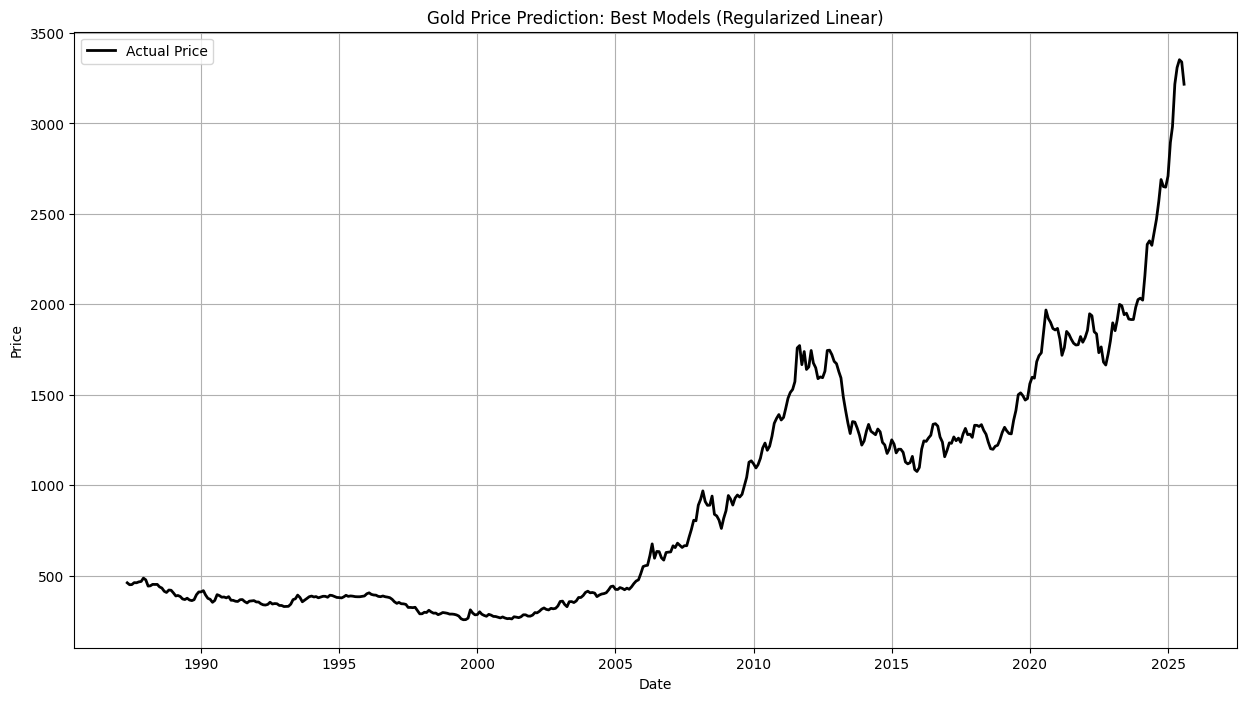

In [13]:
# --- STEP 6: VISUALIZATION ---
plt.figure(figsize=(15, 8))
plt.plot(test_data.index, y_test, label='Actual Price', color='black', linewidth=2)

for name, model in best_estimators.items():
    pred = model.predict(X_test)

# Convert results list to DataFrame
results_df = pd.DataFrame(results)

# Optional: sort by RMSE
results_df = results_df.sort_values(by="RMSE")

results_df

if not results_df.empty:
    model_rmse = results_df.loc[
    results_df['Model'] == name, 'RMSE'
    ].iloc[0]

if model_rmse < 500:
            plt.plot(
                test_data.index,
                pred,
                label=f'{name} (RMSE: {model_rmse:.0f})',
                alpha=0.8,
                linestyle='--'
            )

plt.title('Gold Price Prediction: Best Models (Regularized Linear)')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()


In [14]:

performance = []

for name, model in best_estimators.items():
    # Predictions
    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    # Metrics
    train_r2 = r2_score(y_train, train_pred)
    test_r2  = r2_score(y_test, test_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse  = np.sqrt(mean_squared_error(y_test, test_pred))

    performance.append({
        "Model": name,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse
    })

# Convert to DataFrame
performance_df = pd.DataFrame(performance)

# Show results
performance_df


,Model,Train R2,Test R2,Train RMSE,Test RMSE
0,Ridge (L2),0.992421,0.996445,7.969873,39.775933
1,Lasso (L1),0.992362,0.996436,8.000546,39.828241
2,ElasticNet,0.992049,0.996232,8.162803,40.949086
3,Random Forest,0.997761,-0.184495,4.331305,726.043256
4,SVR,0.563734,-1.346419,60.466187,1021.877280
5,Decision Tree,0.999982,-0.112419,0.388601,703.607120


In [15]:
performance_df["Test Accuracy (%)"] = performance_df["Test R2"] * 100
performance_df


,Model,Train R2,Test R2,Train RMSE,Test RMSE,Test Accuracy (%)
0,Ridge (L2),0.992421,0.996445,7.969873,39.775933,99.644492
1,Lasso (L1),0.992362,0.996436,8.000546,39.828241,99.643557
2,ElasticNet,0.992049,0.996232,8.162803,40.949086,99.623212
3,Random Forest,0.997761,-0.184495,4.331305,726.043256,-18.449462
4,SVR,0.563734,-1.346419,60.466187,1021.877280,-134.641912
5,Decision Tree,0.999982,-0.112419,0.388601,703.607120,-11.241940


In [16]:
final_model = best_estimators["Ridge (L2)"]

In [17]:
LAGS = 12

def create_lags(df, target_col, lags):
    df = df.copy()
    for lag in range(1, lags + 1):
        df[f"lag_{lag}"] = df[target_col].shift(lag)
    return df


In [18]:
# Full dataset jahan last known prices hain
df_lagged = create_lags(df, "Price", LAGS)

# Last available row (jahan saare lags filled hon)
latest_row = df_lagged.dropna().iloc[-1]

# Model input (sirf X columns)
X_new = latest_row[X_train.columns].to_frame().T


In [19]:
prediction = final_model.predict(X_new)
print("Next Predicted Price:", prediction[0])

Next Predicted Price: 3323.970949033059


In [20]:
def create_lag_features(df, target_col, n_lags=12):
    df = df.copy()
    for lag in range(1, n_lags + 1):
        df[f"lag_{lag}"] = df[target_col].shift(lag)
    return df


In [21]:
def predict_next_price(real_data_df, model, X_train_columns, target_col="Price", n_lags=12):
    """
    real_data_df: full historical data (must include target_col)
    model: trained model (Ridge / Lasso)
    X_train_columns: columns used during training
    """

    # Create lag features
    df_lagged = create_lag_features(real_data_df, target_col, n_lags)

    # Last valid row (jahan saare lags available hon)
    latest_row = df_lagged.dropna().iloc[-1]

    # Prepare model input
    X_new = latest_row[X_train_columns].to_frame().T

    # Predict
    prediction = model.predict(X_new)

    return prediction[0]


In [22]:
# df = aap ka real full dataset (historical gold prices)
# Must include "Price" column

next_price = predict_next_price(
    real_data_df=df,
    model=final_model,
    X_train_columns=X_train.columns,
    target_col="Price",
    n_lags=12
)

print("📈 Predicted Next Gold Price:", round(next_price, 2))


📈 Predicted Next Gold Price: 3323.97


In [23]:
last_actual_price = df["Price"].iloc[-1]

print("Last Actual Price :", last_actual_price)
print("Next Predicted Price:", round(next_price, 2))


Last Actual Price : 3217.23
Next Predicted Price: 3323.97


In [24]:
def forecast_n_steps(df, model, X_cols, steps=7, target_col="Price", n_lags=12):
    df_future = df.copy()

    forecasts = []

    for _ in range(steps):
        df_lagged = create_lag_features(df_future, target_col, n_lags)
        latest = df_lagged.dropna().iloc[-1]
        X_new = latest[X_cols].to_frame().T

        pred = model.predict(X_new)[0]
        forecasts.append(pred)

        # Append prediction as new row
        new_row = df_future.iloc[-1:].copy()
        new_row[target_col] = pred
        df_future = pd.concat([df_future, new_row], ignore_index=True)

    return forecasts


In [25]:
future_7_days = forecast_n_steps(
    df,
    final_model,
    X_train.columns,
    steps=7
)

future_7_days


[np.float64(3323.970949033059),
 np.float64(3242.4009413079148),
 np.float64(3397.3763353419263),
 np.float64(3238.259617460633),
 np.float64(3467.0908145674534),
 np.float64(3173.9209830071477),
 np.float64(3563.0966128095906)]

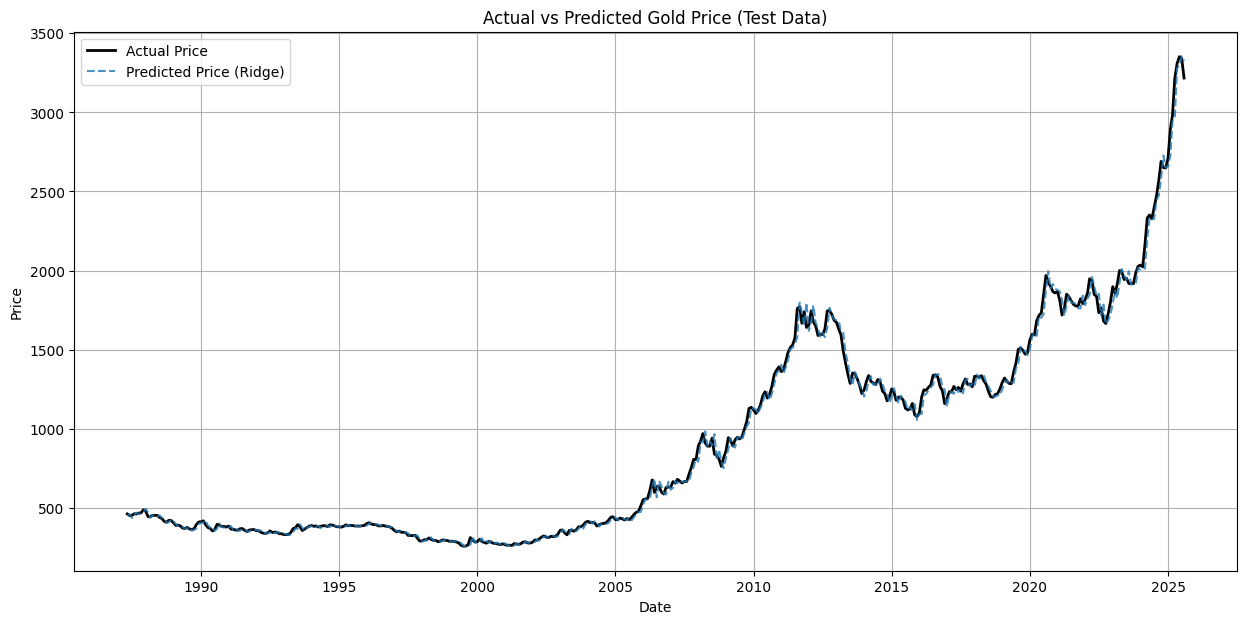

In [26]:
import matplotlib.pyplot as plt

# Predict on test set
test_pred = final_model.predict(X_test)

plt.figure(figsize=(15, 7))

plt.plot(
    test_data.index,
    y_test,
    label="Actual Price",
    color="black",
    linewidth=2
)

plt.plot(
    test_data.index,
    test_pred,
    label="Predicted Price (Ridge)",
    linestyle="--",
    alpha=0.8
)

plt.title("Actual vs Predicted Gold Price (Test Data)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()


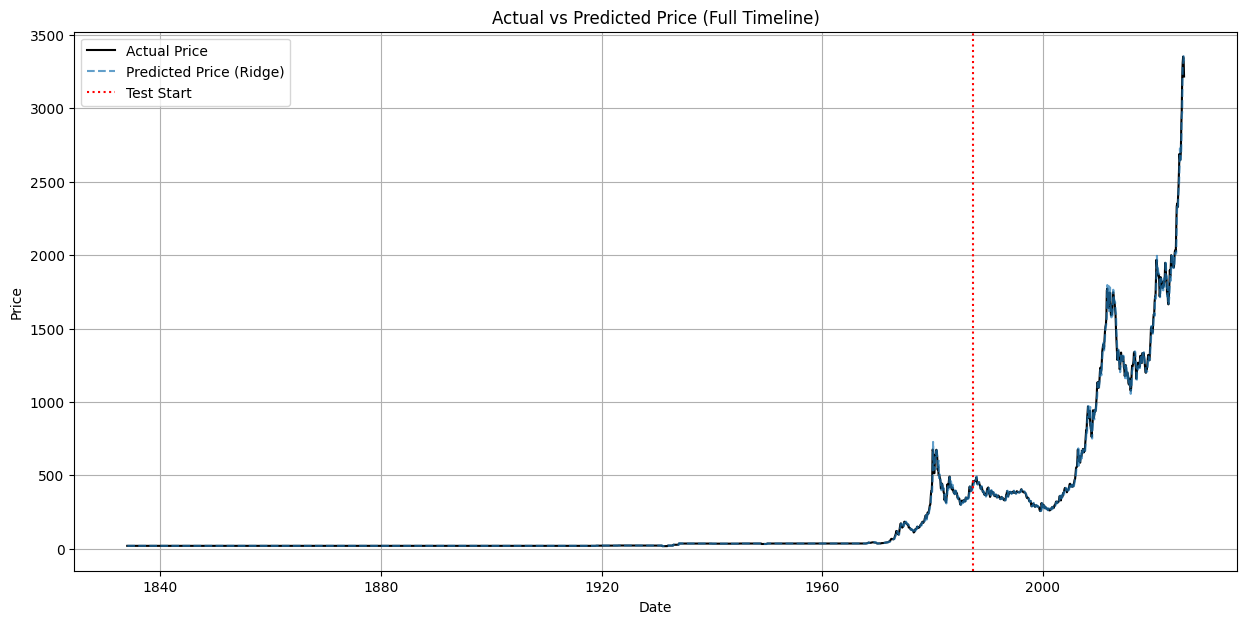

In [27]:
# Predict on full dataset
full_pred = final_model.predict(pd.concat([X_train, X_test]))

plt.figure(figsize=(15, 7))

plt.plot(df.index, df["Price"], label="Actual Price", color="black")

plt.plot(
    df.index,
    full_pred,
    label="Predicted Price (Ridge)",
    linestyle="--",
    alpha=0.7
)

plt.axvline(test_data.index[0], color="red", linestyle=":", label="Test Start")

plt.title("Actual vs Predicted Price (Full Timeline)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()


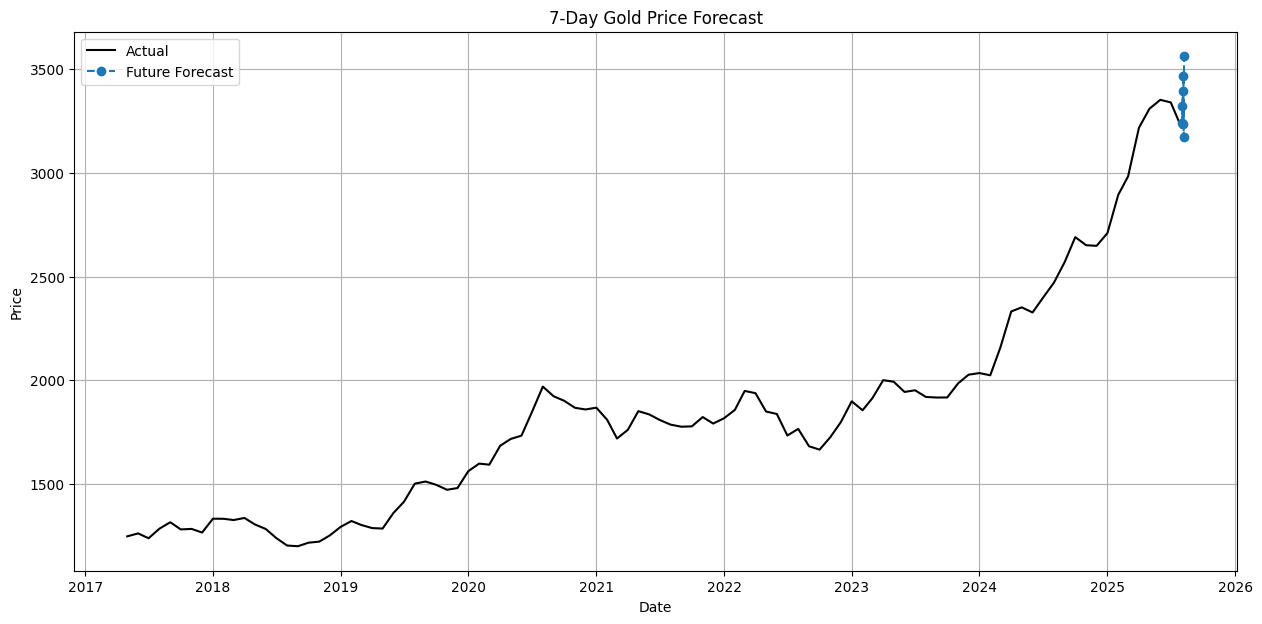

In [28]:
future_preds = forecast_n_steps(
    df,
    final_model,
    X_train.columns,
    steps=7
)

future_index = pd.date_range(
    start=df.index[-1],
    periods=8,
    freq="D"
)[1:]

plt.figure(figsize=(15, 7))
plt.plot(df.index[-100:], df["Price"].iloc[-100:], label="Actual", color="black")
plt.plot(future_index, future_preds, label="Future Forecast", linestyle="--", marker="o")

plt.title("7-Day Gold Price Forecast")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()
